# Cell Painting assay montage

Example: patient `NF0014_T1`, well/FOV `C4-2`.

The Cell Painting assay (Bray et al., 2016) multiplexes several fluorescent stains into a single imaging round, each targeting a distinct cellular compartment. This montage shows each acquired channel individually, labeled with both its dye and the cellular compartment it stains, alongside the pseudocolored RGB composite used for downstream analysis.

In [1]:
import os
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from image_analysis_3D.file_utils.notebook_init_utils import (
    bandicoot_check,
    init_notebook,
)
from matplotlib.gridspec import GridSpec
from microfilm.microplot import microshow

In [2]:
PATIENT = "NF0014_T1"
WELL_FOV = "C4-2"

PIXEL_SIZE_MICRONS = 0.106
SCALE_BAR_LENGTH_MICRONS = 10
PERCENTILE_CLIP = 99.9

# contrast limits (max display value, out of a 0-255 display range) taken from
# the DMSO example for NF0014_T1 C4-2 in ../config/montage_config.toml. Lower
# values dim a channel relative to the others.
CONTRAST_DICT = {
    "AGP": (0, 155),
    "DNA": (0, 125),
    "ER": (0, 155),
    "Mito": (0, 155),
}

# brightness multiplier applied on top of the contrast dict above
BRIGHTNESS_GAIN = 1.8

# Cell Painting channel metadata:
# file suffix -> (channel key, dye/stain name, cellular compartment it labels, microfilm "pure_*" colormap)
CHANNEL_INFO = {
    "405": {
        "key": "DNA",
        "stain": "Hoechst 33342",
        "compartment": "Nucleus (DNA)",
        "color": "cyan",
    },
    "488": {
        "key": "ER",
        "stain": "Concanavalin A",
        "compartment": "Endoplasmic Reticulum",
        "color": "green",
    },
    "555": {
        "key": "AGP",
        "stain": "Phalloidin / WGA",
        "compartment": "Actin, Golgi, Plasma Membrane",
        "color": "magenta",
    },
    "640": {
        "key": "Mito",
        "stain": "MitoTracker Deep Red",
        "compartment": "Mitochondria",
        "color": "red",
    },
}

## Get the paths

In [3]:
root_dir, in_notebook = init_notebook()

image_base_dir = bandicoot_check(
    pathlib.Path(os.path.expanduser("~/mnt/bandicoot")).resolve(), root_dir
)
image_base_dir = image_base_dir / "data"

# use the deconvolved 3D z-stacks (not the pre-computed 2D zmax projections) so
# the max projection can be generated in this notebook
well_fov_dir = pathlib.Path(
    f"{image_base_dir}/{PATIENT}/deconvolved_images/{WELL_FOV}"
).resolve(strict=True)

channel_image_paths = {}
for suffix, info in CHANNEL_INFO.items():
    matches = list(well_fov_dir.glob(f"*_{suffix}.tif"))
    if not matches:
        raise FileNotFoundError(
            f"No image found for channel suffix '{suffix}' in {well_fov_dir}"
        )
    channel_image_paths[info["key"]] = matches[0]

channel_image_paths

{'DNA': PosixPath('/home/lippincm/mnt/bandicoot/NF1_organoid_data/data/NF0014_T1/deconvolved_images/C4-2/C4-2_405.tif'),
 'ER': PosixPath('/home/lippincm/mnt/bandicoot/NF1_organoid_data/data/NF0014_T1/deconvolved_images/C4-2/C4-2_488.tif'),
 'AGP': PosixPath('/home/lippincm/mnt/bandicoot/NF1_organoid_data/data/NF0014_T1/deconvolved_images/C4-2/C4-2_555.tif'),
 'Mito': PosixPath('/home/lippincm/mnt/bandicoot/NF1_organoid_data/data/NF0014_T1/deconvolved_images/C4-2/C4-2_640.tif')}

## Build the montage

In [4]:
# load each channel's 3D (z, y, x) deconvolved stack and max-project it to 2D.
#
# CONTRAST_DICT/BRIGHTNESS_GAIN express where the raw 99.9th-percentile pixel
# value should land on an output 0-255 display scale (a smaller value dims the
# channel). microfilm's "limits" rescale maps [0, limit] -> [0, 1] directly, so
# the raw-value limit that reproduces the same look is:
#   limit = p999 * 255 / (contrast_max * gain)
display_images = {}
channel_limits = {}
for key, image_path in channel_image_paths.items():
    raw_stack = tifffile.imread(image_path)
    zmax_image = np.max(raw_stack, axis=0).astype(np.float32)
    display_images[key] = zmax_image

    p999 = np.percentile(zmax_image, PERCENTILE_CLIP)
    contrast_max = CONTRAST_DICT[key][1]
    channel_limits[key] = [0.0, float(p999 * 255 / (contrast_max * BRIGHTNESS_GAIN))]

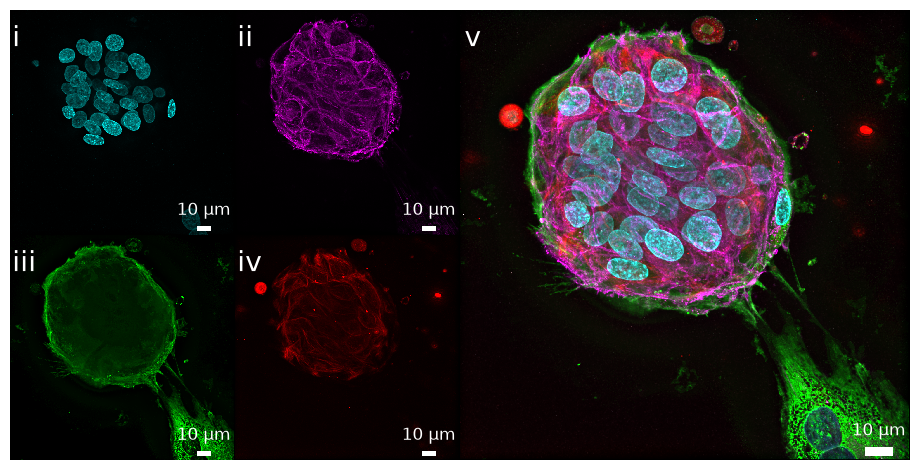

In [5]:
# 2x2 grid of individual channels: DNA (cyan) top-left, AGP top-right,
# ER bottom-left, Mito bottom-right. The composite sits to the side, sized to
# match the full 2x2 block (double the width and height of one channel panel).
# Each panel is labeled i-v in reading order (microfilm's built-in label_text).
#
# microfilm still does the pseudocoloring/scalebar (via microshow(..., ax=ax)),
# but the layout itself is a manual GridSpec since microfilm's Micropanel only
# supports equal-sized grid cells and can't make the composite cell span 2x2.
grid_layout = {
    "DNA": (0, 0),
    "AGP": (0, 1),
    "ER": (1, 0),
    "Mito": (1, 1),
}
panel_labels = {"DNA": "i", "AGP": "ii", "ER": "iii", "Mito": "iv"}
composite_label = "v"
channel_lookup = {info["key"]: info for info in CHANNEL_INFO.values()}
panel_order = ["DNA", "ER", "AGP", "Mito"]

fig = plt.figure(figsize=(9, 4.5))
gs = GridSpec(2, 3, figure=fig, width_ratios=[1, 1, 2], wspace=0.0, hspace=0.0)

for key, (row, col) in grid_layout.items():
    info = channel_lookup[key]
    ax = fig.add_subplot(gs[row, col])
    microshow(
        images=display_images[key],
        cmaps=f"pure_{info['color']}",
        rescale_type="limits",
        limits=channel_limits[key],
        unit="um",
        scalebar_unit_per_pix=PIXEL_SIZE_MICRONS,
        scalebar_size_in_units=SCALE_BAR_LENGTH_MICRONS,
        scalebar_color="white",
        label_text=panel_labels[key],
        label_location="upper left",
        label_color="white",
        label_font_size=20,
        ax=ax,
    )
    ax.set_box_aspect(1)

ax_composite = fig.add_subplot(gs[:, 2])
microshow(
    images=[display_images[key] for key in panel_order],
    cmaps=[f"pure_{channel_lookup[key]['color']}" for key in panel_order],
    rescale_type="limits",
    limits=[channel_limits[key] for key in panel_order],
    proj_type="sum",
    unit="um",
    scalebar_unit_per_pix=PIXEL_SIZE_MICRONS,
    scalebar_size_in_units=SCALE_BAR_LENGTH_MICRONS,
    scalebar_color="white",
    label_text=composite_label,
    label_location="upper left",
    label_color="white",
    label_font_size=20,
    ax=ax_composite,
)
ax_composite.set_box_aspect(1)

plt.subplots_adjust(left=0.0, right=1.0, top=1.0, bottom=0.0, wspace=0.0, hspace=0.0)

output_path = pathlib.Path(
    f"../montages/cell_painting_assay_montage_{PATIENT}_{WELL_FOV}.png"
).resolve()
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()